In [2]:
# BLOQUE 1: Instalación de librerías necesarias
!pip install geopandas
!pip install scikit-learn
!pip install fiona

# BLOQUE 2: Importación de librerías
import pandas as pd
import geopandas as gpd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
#from google.colab import drive
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import silhouette_samples
from scipy.spatial.distance import pdist, squareform
import warnings
warnings.filterwarnings('ignore')


In [3]:
# BLOQUE 2: Montaje de Google Drive
#drive.mount('/content/drive')
import pandas as pd

In [4]:
# BLOQUE 3: Cargar datos
# CAMBIAR ESTA RUTA POR TU ARCHIVO
dict_wrf = pd.read_pickle('/home/ana_luz/remoto/resultados/est_T/dfs/dict_wrf.pkl')
dict_wrf.keys()
dict_wrf['Bouwer BioagroindustriaCba']

# print("Cargando archivo...")
# gdf = gpd.read_file(ruta_archivo)
# print(f"✓ Archivo cargado: {len(gdf)} registros, {len(gdf.columns)} columnas")


,HR2 [%],TEMP [°C],WIND [KM/H],RAINRATE [mm/h],HGT [m],CLDFRA [-],TMN [°C],LH [W/m2],Rad sol [W/m2]
Time,,,,,,,,,
2019-01-01 15:00:00,51.329147,32.020477,4.93752,0.0,469.90796,0.17444,16.95816,252.80441,1067.752100
2019-01-01 16:00:00,47.24927,33.261444,5.298148,0.000711,469.90796,0.406923,16.95816,270.26724,1122.553100
2019-01-01 17:00:00,46.54069,34.04477,5.495615,0.001269,469.90796,0.475982,16.95816,269.50153,1110.959400
2019-01-01 18:00:00,44.832195,34.5907,6.377131,0.001703,469.90796,0.455015,16.95816,255.7309,1035.229400
2019-01-01 19:00:00,47.061302,33.298126,6.248623,0.000881,469.90796,0.465079,16.95816,93.26614,238.299700
...,...,...,...,...,...,...,...,...,...
2025-01-01 10:00:00,72.431694,20.44455,6.272822,2.441806,469.90796,0.610061,16.95816,61.539772,109.127390
2025-01-01 11:00:00,85.12933,19.07904,1.174986,2.970376,469.90796,0.769091,16.95816,32.563534,48.155500
2025-01-01 12:00:00,92.71973,18.164978,3.713634,8.650688,469.90796,0.964807,16.95816,29.486357,15.227822


In [5]:
df_wrf = []

for key in dict_wrf.keys():
    df = dict_wrf[key].copy()
    
    df['estacion'] = key
    
    # asegurar datetime
    df.index = pd.to_datetime(df.index)
    
    # convertir solo columnas numéricas
    cols = df.columns.drop('estacion')
    df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')
    
    # promedio anual
    df_anual = df.resample('Y').mean(numeric_only=True)
    
    # agregar metadata
    df_anual['estacion'] = key
    df_anual['anio'] = df_anual.index.year
    
    # eliminar 2025
    df_anual = df_anual[df_anual['anio'] != 2025]
    
    df_wrf.append(df_anual)

# unir todo
df_wrf = pd.concat(df_wrf)

# promedio entre años por estación
df_final = df_wrf.groupby('estacion').mean(numeric_only=True).reset_index()

df_final

,estacion,HR2 [%],TEMP [°C],WIND [KM/H],RAINRATE [mm/h],HGT [m],CLDFRA [-],TMN [°C],LH [W/m2],Rad sol [W/m2],anio
0,APRHI - Achiras,51.572738,17.558970,6.237421,0.107041,895.59937,0.181038,14.235046,24.251512,261.583690,2021.5
1,APRHI - Piedra Blanca,49.833992,18.687920,4.215439,0.121209,705.65940,0.190138,15.416412,42.083827,259.568688,2021.5
2,APRHI - Reserva Los Chorrillos,55.966539,15.933647,4.472842,0.133279,1247.18570,0.212321,12.753906,36.466666,254.733673,2021.5
3,APRHI- La Rinconada,57.485270,21.593374,3.676285,0.075147,74.77205,0.196679,17.872406,58.232659,268.671210,2021.5
4,APRHI-Chua,41.283343,23.084802,4.009701,0.061811,385.26184,0.161837,19.034576,20.469720,272.176528,2021.5
...,...,...,...,...,...,...,...,...,...,...,...
71,Transito BioagroindustriaCba,53.919427,20.494548,3.930959,0.096267,175.77164,0.191243,16.986023,35.447952,266.006980,2021.5
72,UTN San Francisco BioagroindustriaCba,52.919697,21.303105,4.110228,0.099174,116.83168,0.191384,15.424042,32.889660,266.839390,2021.5
73,Viarago BioagroindustriaCba,44.779198,19.691212,4.220653,0.092133,927.62090,0.179590,15.026825,70.831959,269.105031,2021.5
74,Villa El Chacay - Rio Colecitas Bioagroindustr...,57.062515,14.673086,5.983376,0.120057,1408.61840,0.176649,11.191071,51.276024,267.868347,2021.5


In [6]:
df_final.drop(columns=['anio'], inplace=True)

In [7]:
df_coords = pd.read_csv('/home/ana_luz/remoto/resultados/est_T/dfs/estaciones_lat_lon.csv')
df_coords.head()

,nombre,latitud,longitud
0,San Agustín BioagroindustriaCba,-31.980100,-64.370800
1,Tancacha BioagroindustriaCba,-32.253100,-63.982300
2,Estancia Noble BioagroindustriaCba,-32.099400,-65.054300
3,APRHi - Calmayo,-32.025000,-64.467000
4,Rio_Tercero_BioagroindustriaCba,-32.170078,-64.087732


In [8]:
import re
import unicodedata

def normalizar(texto):
    if pd.isna(texto):
        return texto
    
    texto = texto.lower()
    
    # eliminar acentos
    texto = unicodedata.normalize('NFD', texto)
    texto = ''.join(c for c in texto if unicodedata.category(c) != 'Mn')
    
    # reemplazar TODO lo no alfanumérico por espacio
    texto = re.sub(r'[^a-z0-9]', ' ', texto)
    
    # eliminar espacios múltiples
    texto = re.sub(r'\s+', ' ', texto).strip()
    
    return texto

In [9]:
df_final['match'] = df_final['estacion'].apply(normalizar)
df_coords['match'] = df_coords['nombre'].apply(normalizar)

df_merge = df_final.merge(
    df_coords[['match', 'latitud', 'longitud']],
    on='match',
    how='left'
)

In [10]:
df_merge

,estacion,HR2 [%],TEMP [°C],WIND [KM/H],RAINRATE [mm/h],HGT [m],CLDFRA [-],TMN [°C],LH [W/m2],Rad sol [W/m2],match,latitud,longitud
0,APRHI - Achiras,51.572738,17.558970,6.237421,0.107041,895.59937,0.181038,14.235046,24.251512,261.583690,aprhi achiras,-33.172002,-64.998617
1,APRHI - Piedra Blanca,49.833992,18.687920,4.215439,0.121209,705.65940,0.190138,15.416412,42.083827,259.568688,aprhi piedra blanca,-32.900228,-64.777297
2,APRHI - Reserva Los Chorrillos,55.966539,15.933647,4.472842,0.133279,1247.18570,0.212321,12.753906,36.466666,254.733673,aprhi reserva los chorrillos,-31.391400,-64.635200
3,APRHI- La Rinconada,57.485270,21.593374,3.676285,0.075147,74.77205,0.196679,17.872406,58.232659,268.671210,aprhi la rinconada,-30.174180,-62.944845
4,APRHI-Chua,41.283343,23.084802,4.009701,0.061811,385.26184,0.161837,19.034576,20.469720,272.176528,aprhi chua,-31.698090,-65.302000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,Transito BioagroindustriaCba,53.919427,20.494548,3.930959,0.096267,175.77164,0.191243,16.986023,35.447952,266.006980,transito bioagroindustriacba,-31.420700,-63.193200
72,UTN San Francisco BioagroindustriaCba,52.919697,21.303105,4.110228,0.099174,116.83168,0.191384,15.424042,32.889660,266.839390,utn san francisco bioagroindustriacba,-31.419667,-62.112305
73,Viarago BioagroindustriaCba,44.779198,19.691212,4.220653,0.092133,927.62090,0.179590,15.026825,70.831959,269.105031,viarago bioagroindustriacba,-31.950317,-65.012723
74,Villa El Chacay - Rio Colecitas Bioagroindustr...,57.062515,14.673086,5.983376,0.120057,1408.61840,0.176649,11.191071,51.276024,267.868347,villa el chacay rio colecitas bioagroindustriacba,-32.800611,-64.960972


In [11]:
gdf = gpd.GeoDataFrame(
    df_merge,
    geometry=gpd.points_from_xy(df_merge['longitud'], df_merge['latitud']),
    crs='EPSG:4326'
)

In [12]:
# BLOQUE 4: Selección inteligente de variables
# Excluir variables no útiles
variables_excluir = ['geometry', 'id', 'fid', 'id_grilla', 'CLUSTER_ID']
variables_usar = [col for col in gdf.columns if col not in variables_excluir]

# Solo variables numéricas
datos = gdf[variables_usar].select_dtypes(include=[np.number])
print(f"Variables iniciales: {len(datos.columns)}")
print(f"Variables: {list(datos.columns)}")

# LIMPIEZA DE CORRELACIONES con prioridad a MEDIA
print(f"\n🔍 Analizando correlaciones...")

# Calcular matriz de correlación
corr_matrix = datos.corr().abs()

# Función para decidir qué variable mantener entre dos correlacionadas
def decidir_variable_prioritaria(var1, var2):
    """
    Decide qué variable mantener basándose en prioridades:
    1. La que contenga 'media' en el nombre
      """
    # Convertir a minúsculas para comparación
    v1_lower = var1.lower()
    v2_lower = var2.lower()

    # Prioridad 1: Variables con 'media'
    v1_has_media = 'media' in v1_lower
    v2_has_media = 'media' in v2_lower

    if v1_has_media and not v2_has_media:
        return var1
    elif v2_has_media and not v1_has_media:
        return var2


# Encontrar pares de variables altamente correlacionadas (>0.90)
variables_a_eliminar = set()
correlaciones_encontradas = []

for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        var1 = corr_matrix.columns[i]
        var2 = corr_matrix.columns[j]
        correlacion = corr_matrix.iloc[i, j]

        if correlacion > 0.90:  # Correlación alta
            # Decidir cuál mantener
            mantener = decidir_variable_prioritaria(var1, var2)
            eliminar = var2 if mantener == var1 else var1

            variables_a_eliminar.add(eliminar)
            correlaciones_encontradas.append({
                'eliminada': eliminar,
                'mantenida': mantener,
                'correlacion': correlacion
            })

# Mostrar resultados
if correlaciones_encontradas:
    print(f"Variables correlacionadas encontradas:")
    for item in correlaciones_encontradas:
        print(f"  • Eliminar '{item['eliminada']}' - correlacionada con '{item['mantenida']}' (r={item['correlacion']:.3f})")

    # Eliminar variables correlacionadas
    datos = datos.drop(columns=list(variables_a_eliminar))
    print(f"\n✂️ Eliminadas {len(variables_a_eliminar)} variables por correlación")
else:
    print("✓ No se encontraron correlaciones altas (>0.90)")

print(f"\nVariables finales: {len(datos.columns)}")
print(f"Variables: {list(datos.columns)}")


Variables iniciales: 11
Variables: ['HR2 [%]', 'TEMP [°C]', 'WIND [KM/H]', 'RAINRATE [mm/h]', 'HGT [m]', 'CLDFRA [-]', 'TMN [°C]', 'LH [W/m2]', 'Rad sol [W/m2]', 'latitud', 'longitud']

🔍 Analizando correlaciones...
Variables correlacionadas encontradas:
  • Eliminar 'TEMP [°C]' - correlacionada con 'None' (r=0.910)

✂️ Eliminadas 1 variables por correlación

Variables finales: 10
Variables: ['HR2 [%]', 'WIND [KM/H]', 'RAINRATE [mm/h]', 'HGT [m]', 'CLDFRA [-]', 'TMN [°C]', 'LH [W/m2]', 'Rad sol [W/m2]', 'latitud', 'longitud']


In [13]:
# BLOQUE 5: Limpieza básica
# Eliminar filas con valores nulos
datos_limpios = datos.dropna()
print(f"Registros válidos: {len(datos_limpios)}")

# Normalizar datos
scaler = StandardScaler()
datos_norm = scaler.fit_transform(datos_limpios)

Registros válidos: 76


In [14]:
# BLOQUE 6: Clustering K-means simple
# Probar solo 3 opciones de clusters para ser rápido
print("\nProbando diferentes números de clusters...")
resultados = {}

for k in [4,5,6,7,8,9,10]:  # Solo 3 opciones para ser rápido
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=5)  # Menos inicializaciones
    labels = kmeans.fit_predict(datos_norm)
    silhouette = silhouette_score(datos_norm, labels)
    resultados[k] = {'silhouette': silhouette, 'model': kmeans, 'labels': labels}
    print(f"K={k}: Silhouette = {silhouette:.3f}")

# Seleccionar el mejor
mejor_k = max(resultados.keys(), key=lambda k: resultados[k]['silhouette'])
mejor_score = resultados[mejor_k]['silhouette']
mejor_modelo = resultados[mejor_k]['model']
clusters_finales = resultados[mejor_k]['labels']

print(f"\n🎯 Mejor opción: {mejor_k} clusters (Silhouette: {mejor_score:.3f})")



Probando diferentes números de clusters...
K=4: Silhouette = 0.237
K=5: Silhouette = 0.270
K=6: Silhouette = 0.273
K=7: Silhouette = 0.300
K=8: Silhouette = 0.311
K=9: Silhouette = 0.299
K=10: Silhouette = 0.276

🎯 Mejor opción: 8 clusters (Silhouette: 0.311)



Distribución de clusters:
  Cluster 0: 12
  Cluster 1: 17
  Cluster 2: 5
  Cluster 3: 7
  Cluster 4: 12
  Cluster 5: 10
  Cluster 6: 2
  Cluster 7: 11


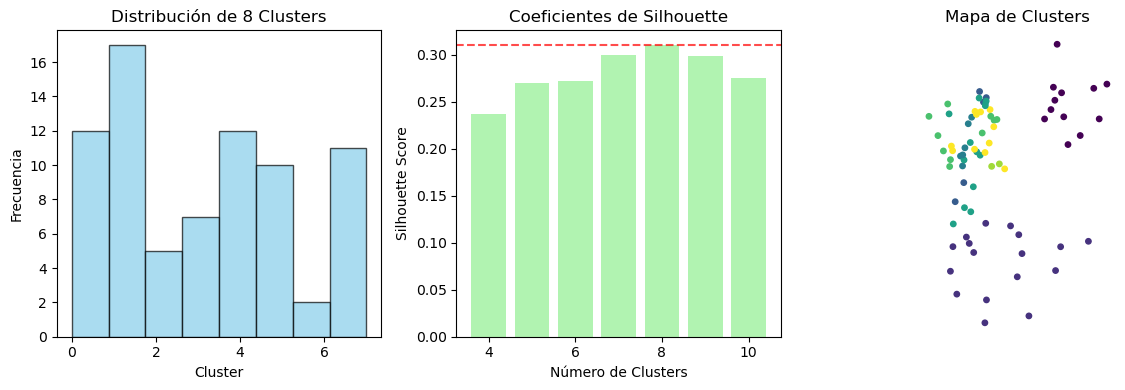


📊 Estadísticas por cluster (primeras 3 variables):

Cluster 0 (n=12):
  HR2 [%]: Media=54.35, Std=1.38
  WIND [KM/H]: Media=3.95, Std=0.12
  RAINRATE [mm/h]: Media=0.09, Std=0.02
  HGT [m]: Media=115.68, Std=27.71
  CLDFRA [-]: Media=0.18, Std=0.01
  TMN [°C]: Media=16.58, Std=0.78
  LH [W/m2]: Media=38.26, Std=13.05
  Rad sol [W/m2]: Media=264.23, Std=3.47
  latitud: Media=-31.16, Std=0.45
  longitud: Media=-62.70, Std=0.41

Cluster 1 (n=17):
  HR2 [%]: Media=49.98, Std=1.50
  WIND [KM/H]: Media=4.39, Std=0.17
  RAINRATE [mm/h]: Media=0.09, Std=0.02
  HGT [m]: Media=271.09, Std=142.61
  CLDFRA [-]: Media=0.17, Std=0.01
  TMN [°C]: Media=16.06, Std=0.64
  LH [W/m2]: Media=30.84, Std=10.64
  Rad sol [W/m2]: Media=260.38, Std=4.45
  latitud: Media=-33.81, Std=0.51
  longitud: Media=-64.04, Std=0.81

Cluster 2 (n=5):
  HR2 [%]: Media=57.56, Std=1.09
  WIND [KM/H]: Media=5.63, Std=0.46
  RAINRATE [mm/h]: Media=0.14, Std=0.02
  HGT [m]: Media=1289.92, Std=209.29
  CLDFRA [-]: Media=0.20, S

In [15]:
# BLOQUE 7: Asignar clusters al GeoDataFrame
gdf_resultado = gdf.copy()
gdf_resultado['cluster'] = -1  # Valor por defecto
gdf_resultado.loc[datos_limpios.index, 'cluster'] = clusters_finales

print(f"\nDistribución de clusters:")
distribucion = gdf_resultado['cluster'].value_counts().sort_index()
for cluster, count in distribucion.items():
    if cluster == -1:
        print(f"  Sin asignar: {count}")
    else:
        print(f"  Cluster {cluster}: {count}")

# BLOQUE 8: Visualización simple
plt.figure(figsize=(12, 4))

# Gráfico 1: Distribución de clusters
plt.subplot(1, 3, 1)
clusters_validos = gdf_resultado[gdf_resultado['cluster'] != -1]['cluster']
plt.hist(clusters_validos, bins=mejor_k, alpha=0.7, color='skyblue', edgecolor='black')
plt.title(f'Distribución de {mejor_k} Clusters')
plt.xlabel('Cluster')
plt.ylabel('Frecuencia')

# Gráfico 2: Comparación de Silhouette scores
plt.subplot(1, 3, 2)
k_values = list(resultados.keys())
silhouette_values = [resultados[k]['silhouette'] for k in k_values]
plt.bar(k_values, silhouette_values, color='lightgreen', alpha=0.7)
plt.axhline(y=mejor_score, color='red', linestyle='--', alpha=0.7)
plt.title('Coeficientes de Silhouette')
plt.xlabel('Número de Clusters')
plt.ylabel('Silhouette Score')

# Gráfico 3: Mapa (si hay geometría)
plt.subplot(1, 3, 3)
if 'geometry' in gdf_resultado.columns and not gdf_resultado.geometry.isna().all():
    gdf_plot = gdf_resultado[gdf_resultado['cluster'] != -1]
    gdf_plot.plot(column='cluster', cmap='viridis', ax=plt.gca(), markersize=15)
    plt.title('Mapa de Clusters')
    plt.axis('off')
else:
    plt.text(0.5, 0.5, 'Sin geometría\ndisponible', ha='center', va='center',
             transform=plt.gca().transAxes, fontsize=12)
    plt.title('Mapa no disponible')

plt.tight_layout()
plt.show()

# BLOQUE 9: Estadísticas básicas por cluster
print(f"\n📊 Estadísticas por cluster (primeras 3 variables):")
primeras_vars = datos.columns  # Solo las primeras 3 para ser rápido

for cluster_id in sorted(gdf_resultado['cluster'].unique()):
    if cluster_id != -1:
        cluster_data = gdf_resultado[gdf_resultado['cluster'] == cluster_id]
        print(f"\nCluster {cluster_id} (n={len(cluster_data)}):")
        for var in primeras_vars:
            if var in cluster_data.columns:
                media = cluster_data[var].mean()
                std = cluster_data[var].std()
                print(f"  {var}: Media={media:.2f}, Std={std:.2f}")

# BLOQUE 10: Reproyección y exportación
print(f"\n💾 Preparando exportación...")

# Reproyectar a EPSG:22174
if gdf_resultado.crs is not None:
    gdf_final = gdf_resultado.to_crs(epsg=22174)
    print(f"✓ Reproyectado a EPSG:22174")
else:
    gdf_final = gdf_resultado
    print("⚠️ Sin CRS original, manteniendo coordenadas originales")

# Exportar
ruta_salida = '/home/ana_luz/remoto/resultados/est_T/dfs/cluster.gpkg'
try:
    gdf_final.to_file(ruta_salida, driver='GPKG')
    print(f"✓ Archivo guardado: {ruta_salida}")

    # Verificar
    verificacion = gpd.read_file(ruta_salida)
    print(f"✓ Verificación: {len(verificacion)} registros guardados")

except Exception as e:
    print(f"❌ Error al guardar: {e}")

# BLOQUE 11: Resumen final
print(f"\n{'='*50}")
print("RESUMEN FINAL")
print(f"{'='*50}")
print(f"📁 Archivo procesado: {len(gdf)} registros")
print(f"🔢 Variables utilizadas: {len(datos.columns)}")
print(f"✅ Registros válidos: {len(datos_limpios)}")
print(f"🎯 Clusters generados: {mejor_k}")
print(f"📊 Calidad (Silhouette): {mejor_score:.3f}")
print(f"💾 Archivo final: {ruta_salida}")

# Interpretación simple del Silhouette
if mejor_score > 0.5:
    calidad = "BUENO"
elif mejor_score > 0.25:
    calidad = "ACEPTABLE"
else:
    calidad = "POBRE - Considera revisar variables"

print(f"🏆 Calidad del clustering: {calidad}")
print(f"{'='*50}")

In [16]:
gdf_resultado

,estacion,HR2 [%],TEMP [°C],WIND [KM/H],RAINRATE [mm/h],HGT [m],CLDFRA [-],TMN [°C],LH [W/m2],Rad sol [W/m2],match,latitud,longitud,geometry,cluster
0,APRHI - Achiras,51.572738,17.558970,6.237421,0.107041,895.59937,0.181038,14.235046,24.251512,261.583690,aprhi achiras,-33.172002,-64.998617,POINT (-64.99862 -33.172),4
1,APRHI - Piedra Blanca,49.833992,18.687920,4.215439,0.121209,705.65940,0.190138,15.416412,42.083827,259.568688,aprhi piedra blanca,-32.900228,-64.777297,POINT (-64.7773 -32.90023),4
2,APRHI - Reserva Los Chorrillos,55.966539,15.933647,4.472842,0.133279,1247.18570,0.212321,12.753906,36.466666,254.733673,aprhi reserva los chorrillos,-31.391400,-64.635200,POINT (-64.6352 -31.3914),3
3,APRHI- La Rinconada,57.485270,21.593374,3.676285,0.075147,74.77205,0.196679,17.872406,58.232659,268.671210,aprhi la rinconada,-30.174180,-62.944845,POINT (-62.94484 -30.17418),0
4,APRHI-Chua,41.283343,23.084802,4.009701,0.061811,385.26184,0.161837,19.034576,20.469720,272.176528,aprhi chua,-31.698090,-65.302000,POINT (-65.302 -31.69809),5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,Transito BioagroindustriaCba,53.919427,20.494548,3.930959,0.096267,175.77164,0.191243,16.986023,35.447952,266.006980,transito bioagroindustriacba,-31.420700,-63.193200,POINT (-63.1932 -31.4207),0
72,UTN San Francisco BioagroindustriaCba,52.919697,21.303105,4.110228,0.099174,116.83168,0.191384,15.424042,32.889660,266.839390,utn san francisco bioagroindustriacba,-31.419667,-62.112305,POINT (-62.11231 -31.41967),0
73,Viarago BioagroindustriaCba,44.779198,19.691212,4.220653,0.092133,927.62090,0.179590,15.026825,70.831959,269.105031,viarago bioagroindustriacba,-31.950317,-65.012723,POINT (-65.01272 -31.95032),7
74,Villa El Chacay - Rio Colecitas Bioagroindustr...,57.062515,14.673086,5.983376,0.120057,1408.61840,0.176649,11.191071,51.276024,267.868347,villa el chacay rio colecitas bioagroindustriacba,-32.800611,-64.960972,POINT (-64.96097 -32.80061),2


In [19]:
gdf_resultado = gdf_resultado.to_crs(epsg=4326)

gdf_resultado.explore(
    column="cluster",
    categorical=True,
    cmap="tab10"
)

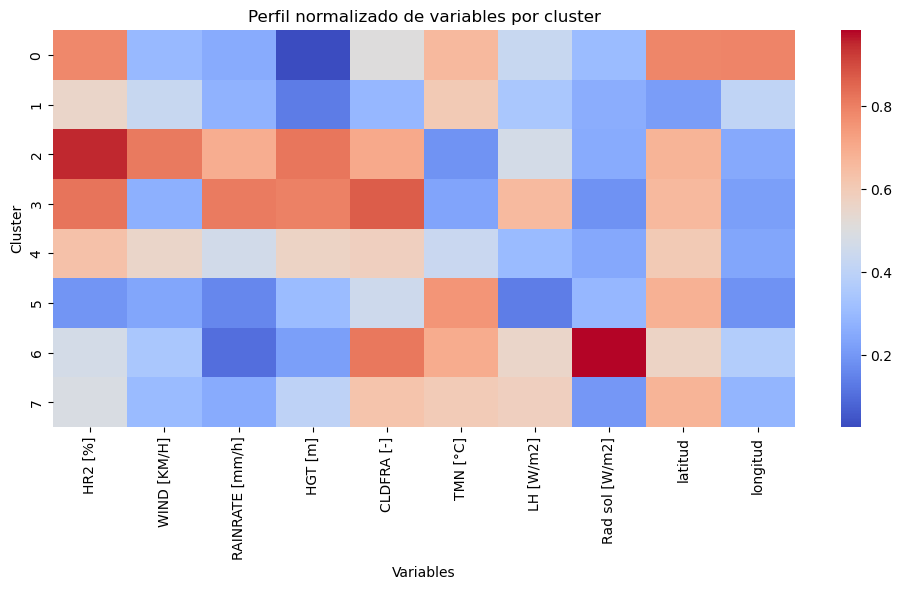

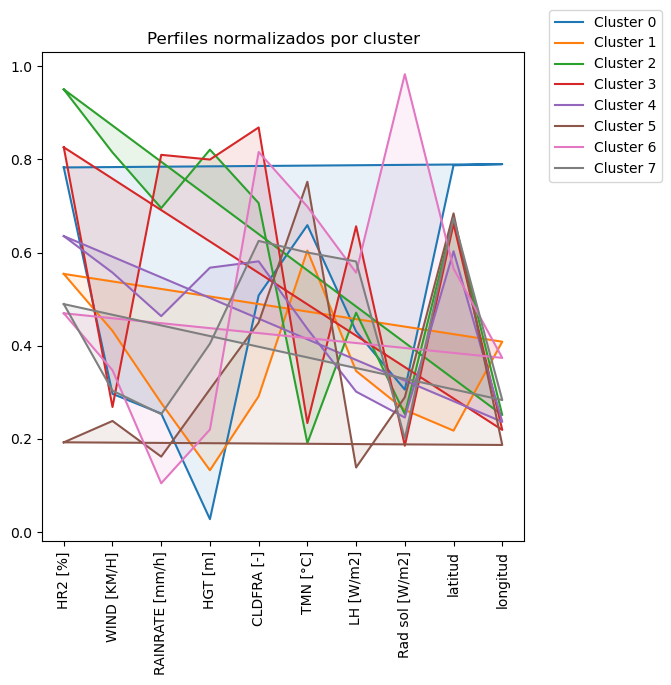

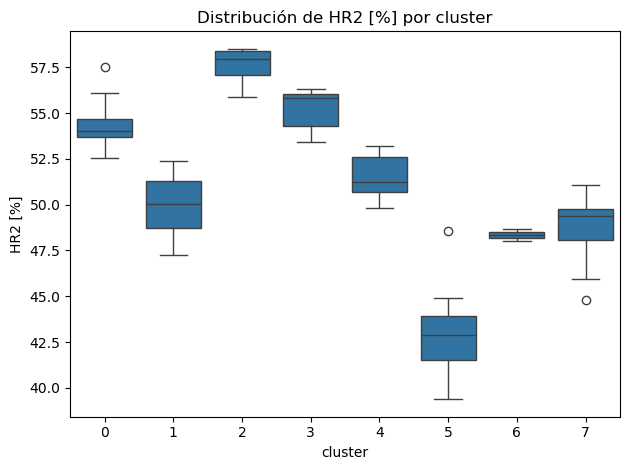

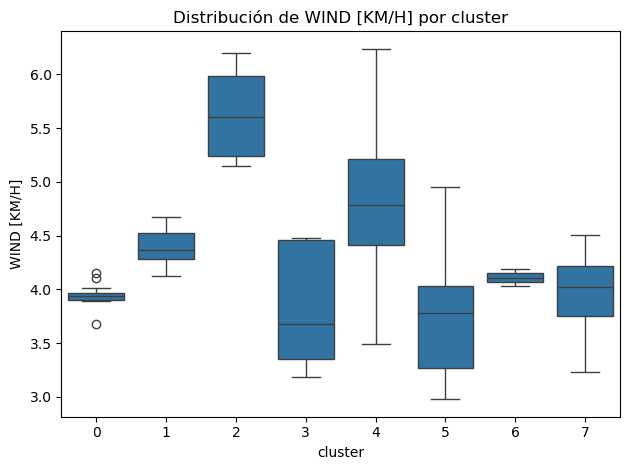

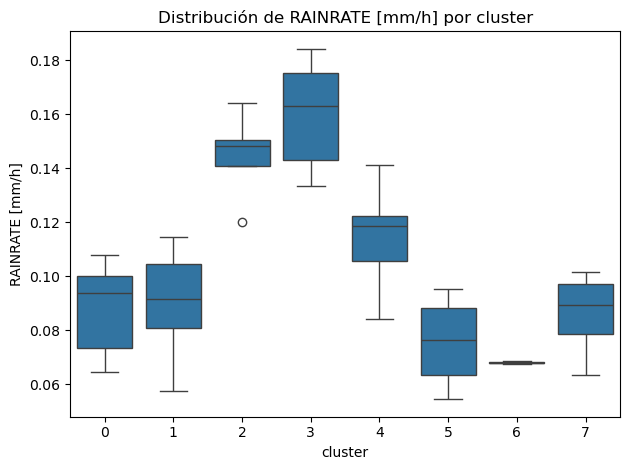

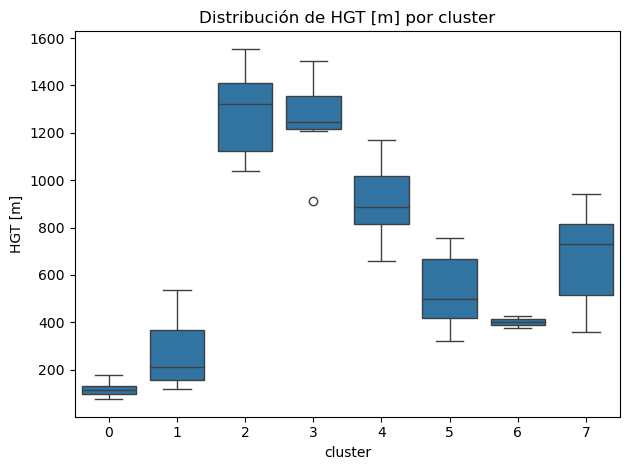

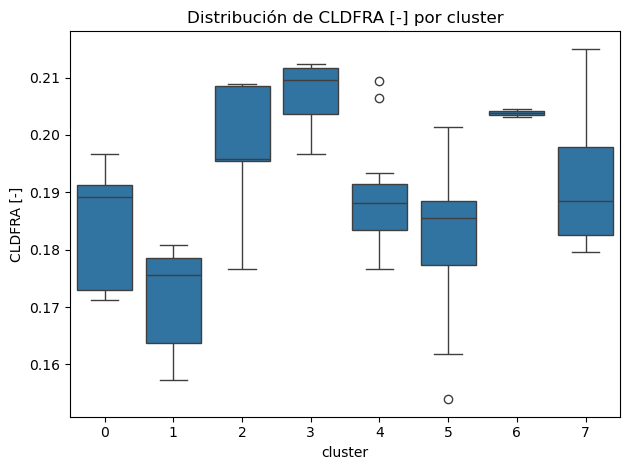

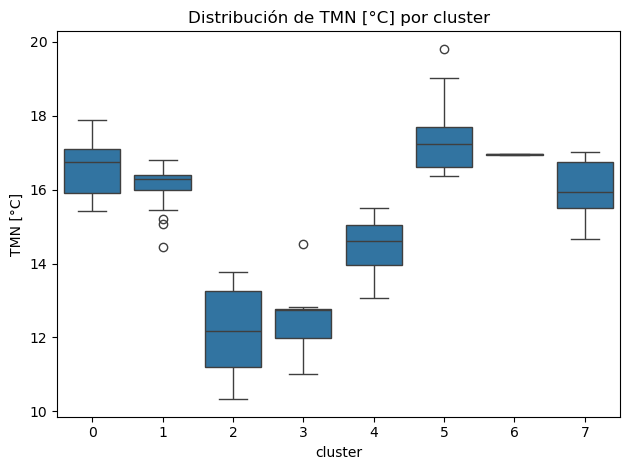

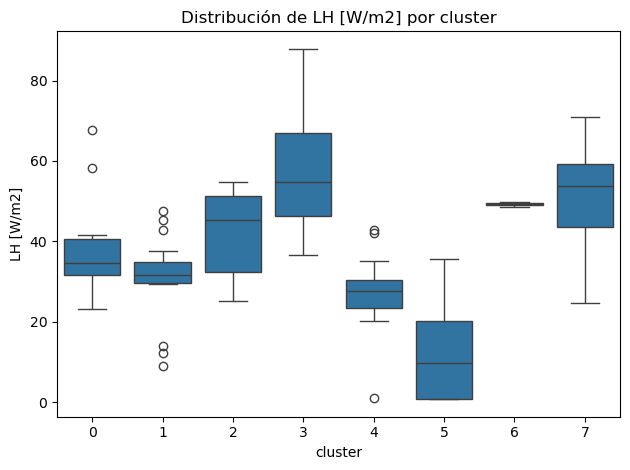

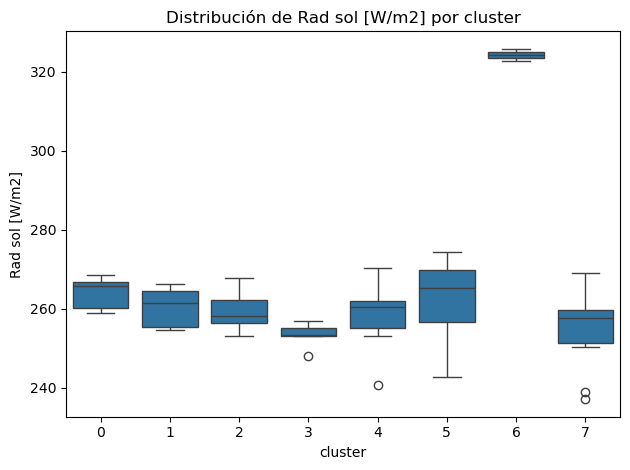

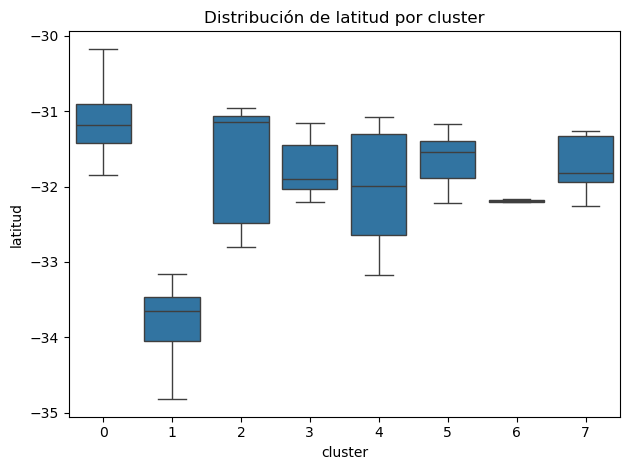

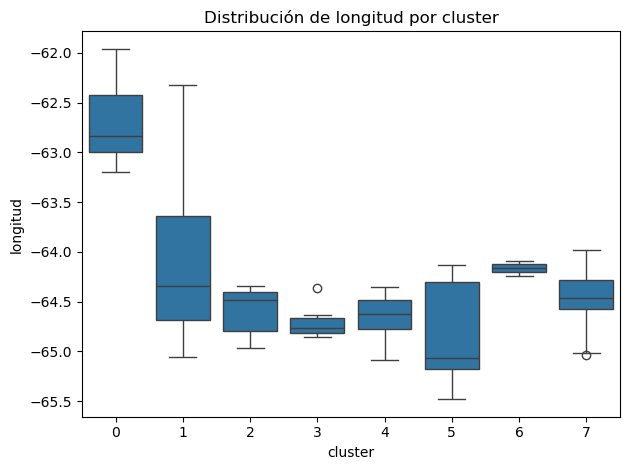

In [45]:
# BLOQUE: análisis y visualización de clusters

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# 1. Filtrar datos válidos (sin cluster = -1)
df_valid = gdf_resultado[gdf_resultado['cluster'] != -1].copy()

# 2. Seleccionar SOLO variables usadas en clustering
vars_cluster = datos.columns.tolist()
df_num = df_valid[vars_cluster]

# 3. Normalización min-max
df_norm = (df_num - df_num.min()) / (df_num.max() - df_num.min())

# 4. Media por cluster (ya normalizado)
df_mean_norm = df_norm.groupby(df_valid['cluster']).mean()

# --------------------------------------------------
# 5. HEATMAP (recomendado)
# --------------------------------------------------

plt.figure(figsize=(10,6))
sns.heatmap(df_mean_norm, cmap='coolwarm', annot=False)
plt.title('Perfil normalizado de variables por cluster')
plt.xlabel('Variables')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. RADAR PLOT (opcional)
# --------------------------------------------------

variables = df_mean_norm.columns
N = len(variables)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

plt.figure(figsize=(7,7))

for i, row in df_mean_norm.iterrows():
    values = row.tolist()
    values += values[:1]
    plt.plot(angles, values, label=f'Cluster {i}')
    plt.fill(angles, values, alpha=0.1)

plt.xticks(angles[:-1], variables, rotation=90)
plt.title('Perfiles normalizados por cluster')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. BOXPLOTS (validación de separación)
# --------------------------------------------------

for var in vars_cluster:
    plt.figure()
    sns.boxplot(
        data=df_valid,
        x='cluster',
        y=var
    )
    plt.title(f'Distribución de {var} por cluster')
    plt.tight_layout()
    plt.show()